Marginal P(Obese): 0.4111
Marginal P(Male): 0.4479
Joint P(Obese AND Male): 0.1714
Independence Check [P(Obese)*P(Male)]: 0.1841
Conditional P(Obese | Male): 0.3826
Conditional P(Obese | Female): 0.4342
Weighted P(Obese): 0.4032
Bayes Theorem P(Male | Obese): 0.4168
Direct Empirical P(Male | Obese): 0.4168
Expected Value E[BMI]: 29.8305
Variance Var(BMI): 54.0393
Covariance(Sleep, BMI): -0.3848


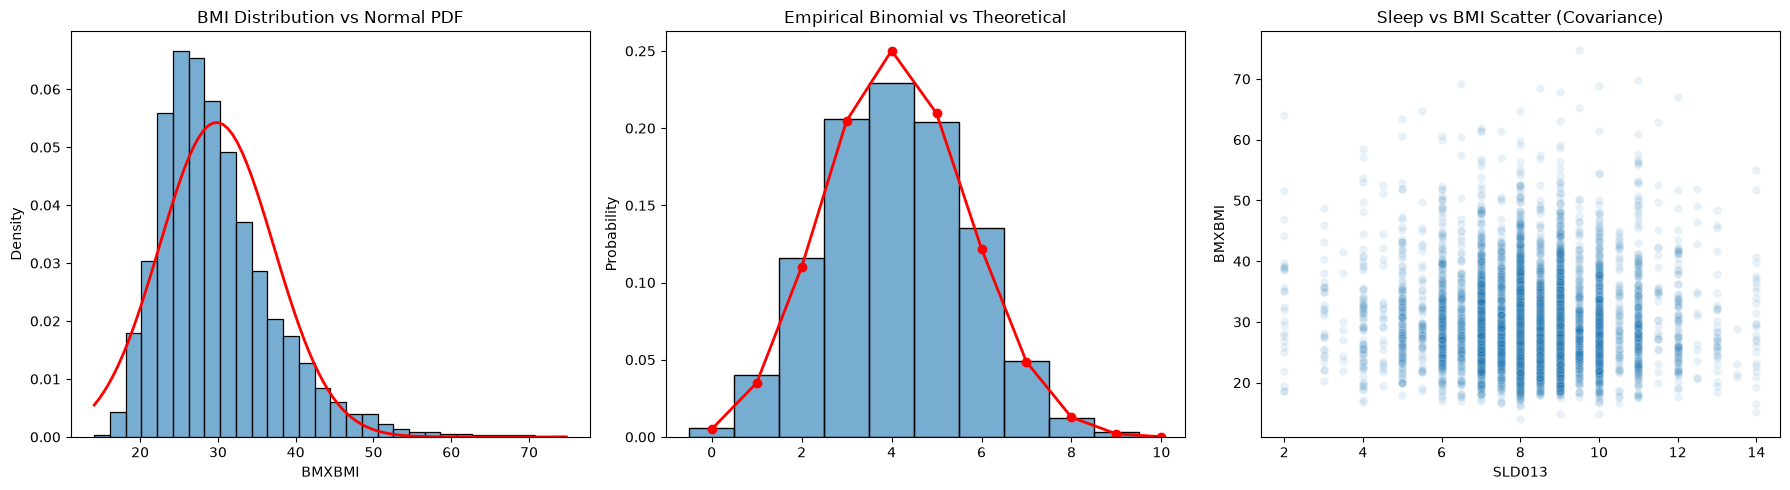

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import binom, norm

demo = pd.read_sas('../data/DEMO_L.xpt')
bmx = pd.read_sas('../data/BMX_L.xpt')
slq = pd.read_sas('../data/SLQ_L.xpt')
paq = pd.read_sas('../data/PAQ_L.xpt')

df = pd.merge(demo, bmx, on='SEQN', how='inner')
df = pd.merge(df, slq, on='SEQN', how='inner')
df = pd.merge(df, paq, on='SEQN', how='inner')

df = df[df['RIDAGEYR'] >= 20]
cols = ['SEQN', 'RIDAGEYR', 'RIAGENDR', 'WTINT2YR', 'WTMEC2YR', 'BMXBMI', 'SLD013', 'PAD790Q', 'PAD790U', 'PAD810Q', 'PAD810U']
df = df[cols]
df = df[~df['SLD013'].isin([77, 99])]
df = df[~df['PAD790Q'].isin([7777, 9999])]
df = df[~df['PAD810Q'].isin([7777, 9999])]
df = df.dropna()

df['Gender'] = df['RIAGENDR'].replace({1.0: 'Male', 2.0: 'Female'})
df['Obese'] = (df['BMXBMI'] >= 30).astype(int)
df['ShortSleep'] = (df['SLD013'] < 7).astype(int)

p_obese = df['Obese'].mean()
p_male = (df['Gender'] == 'Male').mean()
p_female = (df['Gender'] == 'Female').mean()

p_obese_and_male = ((df['Obese'] == 1) & (df['Gender'] == 'Male')).mean()
p_obese_given_male = p_obese_and_male / p_male
p_obese_and_female = ((df['Obese'] == 1) & (df['Gender'] == 'Female')).mean()
p_obese_given_female = p_obese_and_female / p_female

print(f"Marginal P(Obese): {p_obese:.4f}")
print(f"Marginal P(Male): {p_male:.4f}")
print(f"Joint P(Obese AND Male): {p_obese_and_male:.4f}")
print(f"Independence Check [P(Obese)*P(Male)]: {p_obese * p_male:.4f}")
print(f"Conditional P(Obese | Male): {p_obese_given_male:.4f}")
print(f"Conditional P(Obese | Female): {p_obese_given_female:.4f}")

weighted_p_obese = np.average(df['Obese'], weights=df['WTMEC2YR'])
print(f"Weighted P(Obese): {weighted_p_obese:.4f}")

p_male_given_obese_bayes = (p_obese_given_male * p_male) / p_obese
p_male_given_obese_direct = ((df['Obese'] == 1) & (df['Gender'] == 'Male')).mean() / p_obese
print(f"Bayes Theorem P(Male | Obese): {p_male_given_obese_bayes:.4f}")
print(f"Direct Empirical P(Male | Obese): {p_male_given_obese_direct:.4f}")

bmi_mean = df['BMXBMI'].mean()
bmi_var = df['BMXBMI'].var()
print(f"Expected Value E[BMI]: {bmi_mean:.4f}")
print(f"Variance Var(BMI): {bmi_var:.4f}")

cov_matrix = np.cov(df['SLD013'], df['BMXBMI'])
cov_sleep_bmi = cov_matrix[0, 1]
print(f"Covariance(Sleep, BMI): {cov_sleep_bmi:.4f}")

n_trials = 10
n_samples = 1000
np.random.seed(42)
empirical_counts = [np.random.choice(df['Obese'], size=n_trials).sum() for _ in range(n_samples)]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['BMXBMI'], stat='density', bins=30, ax=axes[0], alpha=0.6)
x_val = np.linspace(df['BMXBMI'].min(), df['BMXBMI'].max(), 100)
axes[0].plot(x_val, norm.pdf(x_val, bmi_mean, np.sqrt(bmi_var)), color='red', lw=2)
axes[0].set_title('BMI Distribution vs Normal PDF')

sns.histplot(empirical_counts, stat='probability', discrete=True, ax=axes[1], alpha=0.6)
x_bin = np.arange(0, n_trials + 1)
axes[1].plot(x_bin, binom.pmf(x_bin, n_trials, p_obese), color='red', marker='o', lw=2)
axes[1].set_title('Empirical Binomial vs Theoretical')

sns.scatterplot(x='SLD013', y='BMXBMI', data=df, alpha=0.1, ax=axes[2])
axes[2].set_title('Sleep vs BMI Scatter (Covariance)')

plt.tight_layout()
plt.savefig('../figures/phase2_plots.png')
plt.show()